# Grouped-additive project: governed logistic baseline

[Open this notebook in Google Colab](https://colab.research.google.com/github/neelia26/rare-missense-xai/blob/feature/grouped-additive-model/notebooks/grouped_additive_baseline.ipynb)

This notebook is the readable companion to the reusable Python modules. It verifies the frozen 47-feature primary condition, runs the training-only five-fold gene-grouped logistic-regression baseline, and displays the saved results inline. Validation and test outcomes are not loaded.

## Colab data arrangement

The GitHub repository supplies the code. The processed CSV files are intentionally not stored on GitHub. For Colab, copy the repository's `data/processed` directory to Google Drive so that the Drive folder contains `data/processed/modeling_splits/train_core_no_population.csv` and the other frozen files. Then update `COLAB_DATA_ROOT` below.

In [1]:
from pathlib import Path
import json, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/neelia26/rare-missense-xai.git'
BRANCH = 'feature/grouped-additive-model'

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_ROOT = Path('/content/rare-missense-xai')
    if not REPO_ROOT.exists():
        subprocess.run(['git', 'clone', '--branch', BRANCH, REPO_URL, str(REPO_ROOT)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(REPO_ROOT / 'requirements.txt')], check=True)
    COLAB_DATA_ROOT = Path('/content/drive/MyDrive/rare_missense_modeling')  # edit if needed
    DATA_ROOT = COLAB_DATA_ROOT
else:
    REPO_ROOT = Path.cwd().resolve()
    if REPO_ROOT.name == 'notebooks':
        REPO_ROOT = REPO_ROOT.parent
    DATA_ROOT = REPO_ROOT

sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault('MPLCONFIGDIR', '/tmp/rare_missense_mpl')
print('Repository:', REPO_ROOT)
print('Frozen data root:', DATA_ROOT)

Repository: /Users/neeliamedhani/rare_missense_modeling
Frozen data root: /Users/neeliamedhani/rare_missense_modeling


In [2]:
from src.modeling.common import load_frozen_training_data

frozen = load_frozen_training_data(REPO_ROOT, data_root=DATA_ROOT)
print(f'Training variants: {len(frozen.frame):,}')
print(f'Primary predictors: {len(frozen.features)}')
print('Evidence groups:')
for group, features in frozen.evidence_groups.items():
    print(f'  {group}: {len(features)}')
print('CV fold sizes:', frozen.frame['cv_fold'].value_counts().sort_index().to_dict())

Training variants: 27,727
Primary predictors: 47
Evidence groups:
  conservation: 2
  gene_constraint: 2
  amino_acid_properties: 8
  protein_context: 35
CV fold sizes: {0: 5546, 1: 5549, 2: 5543, 3: 5545, 4: 5544}


In [3]:
from src.modeling.logistic_baseline import run_logistic_baseline

summary = run_logistic_baseline(REPO_ROOT, data_root=DATA_ROOT)
summary

{'status': 'training_only_complete',
 'model': 'logistic_regression_baseline',
 'feature_count': 47,
 'training_rows': 27727,
 'selected_C': 1.0,
 'selected_threshold': 0.495,
 'calibration_intercept': 0.02388588717795247,
 'calibration_slope': 0.9833502614623056,
 'pooled_oof_metrics_at_0_5': {'threshold': 0.5,
  'mcc': 0.7211884186233658,
  'roc_auc': 0.93277020665857,
  'pr_auc': 0.9254155672809896,
  'brier': 0.10130154390109218,
  'accuracy': 0.8604969884949688,
  'sensitivity': 0.8756613756613757,
  'specificity': 0.8450622225456662,
  'precision': 0.8519059543683918,
  'f1': 0.8636203370707285,
  'tn': 11612,
  'fp': 2129,
  'fn': 1739,
  'tp': 12247},
 'pooled_oof_metrics_at_selected_threshold': {'threshold': 0.495,
  'mcc': 0.7220621056778876,
  'roc_auc': 0.93277020665857,
  'pr_auc': 0.9254155672809896,
  'brier': 0.10130154390109218,
  'accuracy': 0.8608937137086594,
  'sensitivity': 0.8780923780923781,
  'specificity': 0.8433883996797904,
  'precision': 0.8508972493591076,

In [4]:
import pandas as pd
from IPython.display import display, Image

OUTPUT = REPO_ROOT / 'outputs/grouped_additive_model/01_logistic_baseline'
print('Hyperparameter comparison')
display(pd.read_csv(OUTPUT / 'hyperparameter_search.csv'))
print('Selected-model fold results')
display(pd.read_csv(OUTPUT / 'fold_metrics.csv'))

Hyperparameter comparison


,C,mean_fold_mcc,sd_fold_mcc,pooled_oof_mcc_at_0_5
0,1.00,0.721596,0.012622,0.721188
1,10.00,0.721491,0.012471,0.721102
2,0.10,0.721073,0.012119,0.720646
3,0.01,0.714948,0.009817,0.714517


Selected-model fold results


,threshold,mcc,roc_auc,pr_auc,brier,accuracy,sensitivity,specificity,precision,f1,...,fp,fn,tp,C,fold,train_rows,holdout_rows,train_genes,holdout_genes,fit_seconds
0,0.5,0.708590,0.924648,0.916594,0.107787,0.854309,0.857756,0.850801,0.854093,0.855920,...,410,398,2400,1.0,0,22181,5546,4110,1096,0.133523
1,0.5,0.721467,0.933248,0.923183,0.101014,0.860696,0.855254,0.866230,0.866715,0.860946,...,368,405,2393,1.0,1,22178,5549,4158,1048,0.134474
2,0.5,0.709466,0.932740,0.927523,0.102419,0.854591,0.872318,0.836549,0.844529,0.858198,...,449,357,2439,1.0,2,22184,5543,4185,1021,0.131547
3,0.5,0.735180,0.936557,0.923803,0.096737,0.867448,0.884519,0.850073,0.857242,0.870667,...,412,323,2474,1.0,3,22182,5545,4216,990,0.132829
4,0.5,0.733275,0.938915,0.936560,0.098550,0.865440,0.908473,0.821624,0.838337,0.871997,...,490,256,2541,1.0,4,22183,5544,4155,1051,0.121058


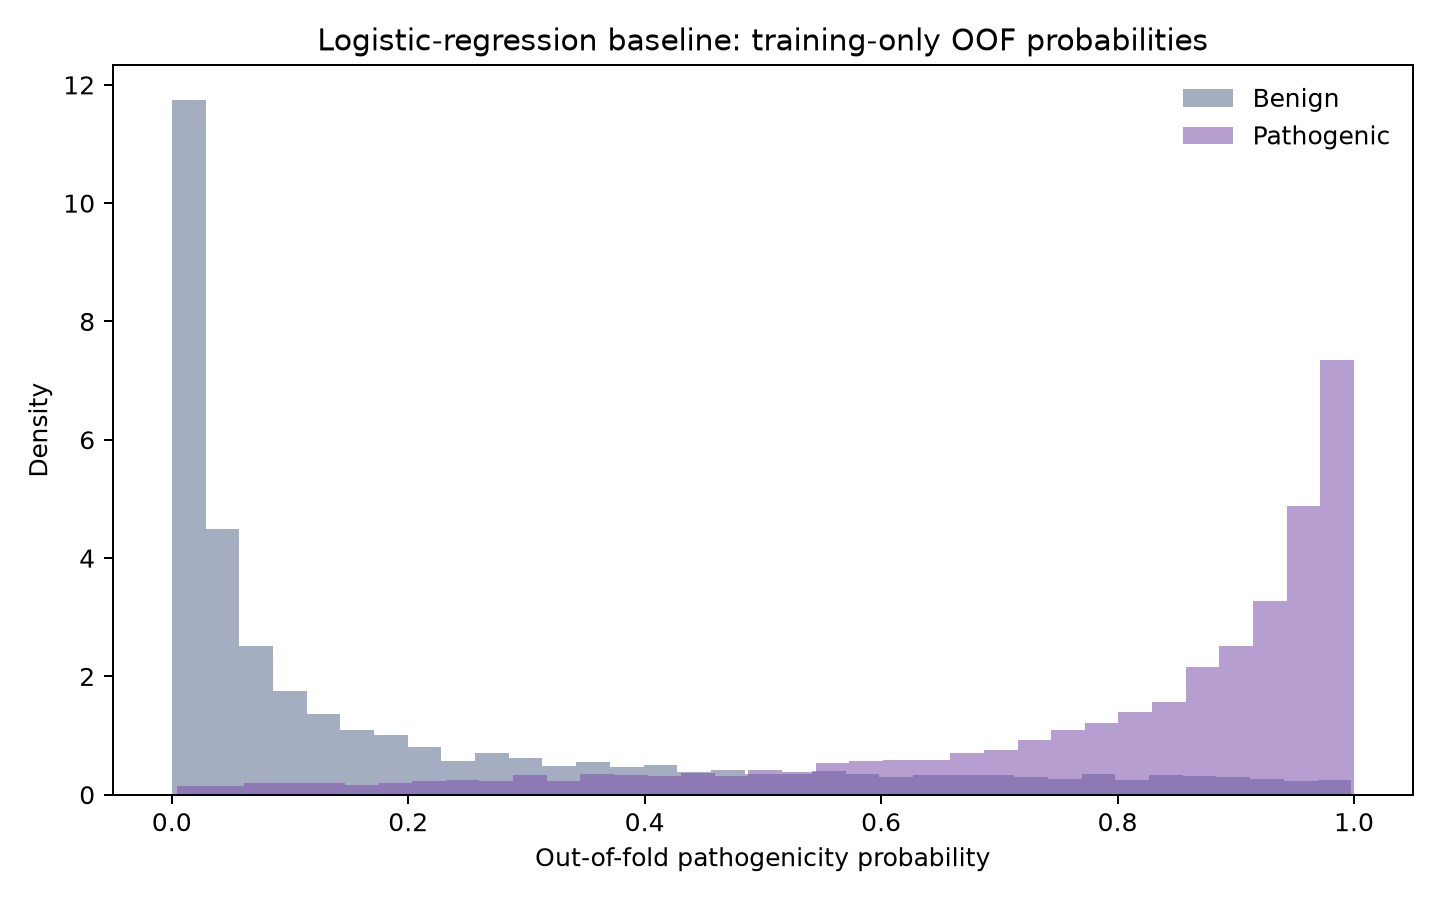

In [5]:
display(Image(filename=str(OUTPUT / 'oof_probability_distribution.png')))

In [6]:
coefficients = pd.read_csv(OUTPUT / 'fold_coefficients.csv')
coefficient_summary = (coefficients.groupby('feature')['coefficient']
                       .agg(['mean', 'std'])
                       .assign(abs_mean=lambda table: table['mean'].abs())
                       .sort_values('abs_mean', ascending=False))
display(coefficient_summary.head(20))
print('Saved full-training coefficients')
display(pd.read_csv(OUTPUT / 'fitted_training_coefficients.csv').assign(abs_coefficient=lambda table: table.coefficient.abs()).sort_values('abs_coefficient', ascending=False).head(20))

,mean,std,abs_mean
feature,,,
uniprot_feature_intramembrane,2.192526,0.115334,2.192526
uniprot_feature_binding_site,2.103561,0.172799,2.103561
uniprot_feature_active_site,2.041576,0.208265,2.041576
uniprot_feature_dna_binding,1.623619,0.080977,1.623619
conservation_phylop100way,1.443950,0.019109,1.443950
uniprot_feature_motif,1.410425,0.100630,1.410425
uniprot_feature_helix,1.218973,0.066782,1.218973
uniprot_feature_beta_strand,1.166725,0.044973,1.166725
uniprot_feature_transmembrane,1.079048,0.133079,1.079048


Saved full-training coefficients


,feature,coefficient,abs_coefficient
32,uniprot_feature_intramembrane,2.312185,2.312185
20,uniprot_feature_active_site,2.265816,2.265816
22,uniprot_feature_binding_site,2.139077,2.139077
27,uniprot_feature_dna_binding,1.635623,1.635623
0,conservation_phylop100way,1.443453,1.443453
35,uniprot_feature_motif,1.440566,1.440566
31,uniprot_feature_helix,1.219636,1.219636
21,uniprot_feature_beta_strand,1.171206,1.171206
41,uniprot_feature_site,1.100858,1.100858
44,uniprot_feature_transmembrane,1.091056,1.091056


## Interpretation boundary

These are training-only out-of-fold development results. Coefficients describe conditional associations in the fitted linear baseline; they are not causal biological effects. No validation or test result is shown here. The grouped additive model will later use the same frozen inputs and folds while replacing the single linear predictor with one inspectable nonlinear contribution per evidence group.